# Cuidar da pele no Brasil cabe no bolso?
### Preço, acesso e procura por protetor solar facial no mercado brasileiro

**Autora:** Giovana Lauriano Cenerini

---

## 1. Contexto e problema

O Brasil é um país tropical, com sol forte o ano inteiro, e a Sociedade Brasileira de Dermatologia recomenda protetor solar **todos os dias**, na quantidade de uma colher de chá para rosto, cabeça e pescoço. Mas quanto custa seguir essa recomendação? E o produto ideal para cada tipo de pele está ao alcance de quem ganha um salário mínimo?

Neste projeto respondo cinco perguntas com dados reais:

1. **Preço:** quanto custa proteger o rosto no Brasil, e como o preço varia entre marcas populares, dermocosméticas e marcas próprias de farmácia?
2. **Acessibilidade:** quanto o uso diário custa por mês e quanto isso representa do salário mínimo?
3. **Tipos de pele:** quem tem pele oleosa, muito comum no clima brasileiro, encontra opções baratas?
4. **Comportamento de consumo:** quando e onde o brasileiro mais procura protetor solar facial? E os produtos para pele ficaram mais caros que o resto da economia?
5. **Extras:** ativos como niacinamida e vitamina C, cor ou toque seco deixam o protetor mais caro?

**Fontes de dados (todas reais):**

| Fonte | O que traz |
|---|---|
| Levantamento próprio | preço, tamanho, FPS, tipo de pele, acabamento, ativos e tipo de filtro (pela lista de ingredientes do site oficial de cada marca) de protetores faciais vendidos no Brasil, com link e data de cada coleta. Preço cheio (sem desconto de Black Friday) tirado da Drogaria São Paulo, que mostra 'De' e 'Por' (exceções: Needs na Drogasil; Sallve e Principia PS-05 nos sites das marcas) |
| IBGE – IPCA | inflação mensal do subitem "Produto para pele" e do índice geral |
| Salário mínimo | valores oficiais definidos por decreto |
| Google Trends | interesse de busca por protetor solar facial no Brasil, por semana e por estado |

## 2. Configuração

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

DATA_DIR = Path("../data")
IMG_DIR = Path("../images")
IMG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "font.size": 11,
})
CORES_FAIXA = {
    "Popular": "#2a6f97",
    "Marca própria": "#2a9d8f",
    "Dermocosmético": "#8e5ea2",
    "Premium": "#e07a2e",
}
COR_DESTAQUE = "#e07a2e"
COR_NEUTRA = "#2a6f97"
pd.set_option("display.float_format", "{:,.2f}".format)


def salvar(fig, nome):
    fig.savefig(IMG_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")


def reais(x, casas=2):
    """Formata número como R$ no padrão brasileiro."""
    texto = f"{x:,.{casas}f}"
    return "R$ " + texto.replace(",", "X").replace(".", ",").replace("X", ".")


def eixo_reais(ax, eixo="y", casas=0):
    fmt = mticker.FuncFormatter(lambda v, _: reais(v, casas))
    (ax.yaxis if eixo == "y" else ax.xaxis).set_major_formatter(fmt)

### Premissas
Todos os números que dependem de uma escolha minha ficam aqui, para quem ler poder mudar e rodar de novo.

- **Salário mínimo 2026:** R$ 1.621 (Decreto 12.797/2025).
- **Quantidade por aplicação:** a SBD recomenda uma colher de chá rasa para rosto, cabeça e pescoço. Uma colher de chá equivale a cerca de 5 ml. Como muita gente usa menos que isso, calculo dois cenários: o **recomendado** (1 colher, cerca de 5 ml) e um **econômico** (meia colher, cerca de 2,5 ml).
- **Uma aplicação por dia, 30 dias por mês.** A reaplicação ao longo do dia ficou de fora, então o custo real de quem reaplica é maior.
- Produtos vendidos em gramas foram tratados como se 1 g = 1 ml. Para cremes e loções, a diferença é pequena.

In [2]:
SALARIO_MINIMO = 1621.00
DOSES_ML = {"Recomendado (1 colher de chá ≈ 5 ml)": 5.0,
            "Econômico (½ colher ≈ 2,5 ml)": 2.5}
DIAS_MES = 30

---
## 3. Levantamento de preços

A planilha de coleta foi preenchida à mão a partir dos sites das lojas, com o link e a data de cada preço. Baixe-a como `.xlsx` e salve em `data/coleta_protetores.xlsx`.

In [3]:
bruto = pd.read_excel(DATA_DIR / "coleta_protetores.xlsx", sheet_name="Coleta")

nomes = {
    "Marca": "marca", "Produto (nome exato)": "produto", "Faixa da marca": "faixa",
    "Preço cheio (R$)": "preco", "Preço promocional (R$)": "preco_promo",
    "Quantidade": "quantidade", "Unidade": "unidade", "FPS": "fps",
    "Tipo de pele indicado": "tipo_pele", "Acabamento": "acabamento",
    "Com cor?": "com_cor", "Niacinamida": "niacinamida", "Vitamina C": "vitamina_c",
    "Ácido hialurônico": "acido_hialuronico", "Vitamina E": "vitamina_e",
    "Outros ativos": "outros_ativos", "Proteção UVA (PPD)": "ppd", "Tipo de filtro": "tipo_filtro",
    "Loja": "loja", "Link da página": "link",
    "Data da coleta": "data_coleta", "Observações": "obs",
    "Lista de ingredientes (INCI)": "inci", "Fonte da lista": "fonte_inci",
}
df = bruto.rename(columns=nomes)[list(nomes.values())].copy()

for c in ["preco", "preco_promo", "quantidade", "fps", "ppd"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Caixas de marcar viram verdadeiro/falso (o Excel pode trazer TRUE, VERDADEIRO, 1...)
ATIVOS = {"niacinamida": "Niacinamida", "vitamina_c": "Vitamina C",
          "acido_hialuronico": "Ácido hialurônico", "vitamina_e": "Vitamina E"}
for c in ATIVOS:
    df[c] = df[c].astype(str).str.strip().str.upper().isin(["TRUE", "VERDADEIRO", "1", "1.0", "SIM"])

# Linhas sugeridas que não foram preenchidas ficam de fora
incompletas = df[df["preco"].isna() | df["quantidade"].isna() | df["produto"].isna()]
df = df.drop(incompletas.index).reset_index(drop=True)
print(f"Produtos com dados completos: {len(df)}")
print(f"Linhas descartadas por falta de preço, quantidade ou nome: {len(incompletas)}")

Produtos com dados completos: 40
Linhas descartadas por falta de preço, quantidade ou nome: 0


**Checagens de qualidade.** Antes de analisar, confiro se há algo estranho: produto repetido, preço por ml fora do comum, campos de categoria vazios.

In [4]:
df["preco_ml"] = df["preco"] / df["quantidade"]
for c in ["tipo_pele", "acabamento", "faixa", "com_cor", "tipo_filtro"]:
    df[c] = df[c].fillna("Não informado")
df["outros_ativos"] = df["outros_ativos"].fillna("").astype(str).str.strip()

print("Produtos repetidos:", df.duplicated(["marca", "produto"]).sum())
print("Período da coleta:", df["data_coleta"].min(), "a", df["data_coleta"].max())
print("Lojas usadas:", df["loja"].value_counts().to_dict())
print("Linhas por marca:", df["marca"].value_counts().to_dict())
print("Preços da Drogasil (preço cheio conferido em 26/11/2026):", int(df["loja"].astype(str).str.startswith("Drogasil").sum()), "linhas")

q1, q3 = df["preco_ml"].quantile([0.25, 0.75])
fora = df[(df["preco_ml"] < q1 - 1.5 * (q3 - q1)) | (df["preco_ml"] > q3 + 1.5 * (q3 - q1))]
print(f"\nPreço por ml fora do padrão (vale conferir na planilha): {len(fora)}")
fora[["marca", "produto", "preco", "quantidade", "preco_ml"]]

Produtos repetidos: 0
Período da coleta: 2026-11-24 00:00:00 a 2026-11-25 00:00:00
Lojas usadas: {'Drogaria São Paulo (site)': 29, 'Drogasil (site)': 9, 'Sallve (site oficial)': 1, 'Site oficial (preço sugerido)': 1}
Linhas por marca: {'Needs (Raia/Drogasil)': 9, 'La Roche-Posay': 4, 'Nivea': 3, 'Episol (Mantecorp)': 2, 'Isdin': 2, 'Avène': 2, 'Darrow': 2, 'Eucerin': 2, 'Vichy': 2, 'Principia': 2, 'Adcos': 2, 'Sallve': 2, 'Neutrogena': 2, 'Bioderma': 1, 'Cenoura & Bronze': 1, 'Bioré': 1, 'Creamy': 1}
Preços da Drogasil (preço cheio conferido em 26/11/2026): 9 linhas

Preço por ml fora do padrão (vale conferir na planilha): 2


,marca,produto,preco,quantidade,preco_ml
9,Adcos,Aqua Fluid FPS 50 Antioleosidade Incolor 40ml,149.00,40,3.73
31,Adcos,Aqua Fluid FPS 50 Antioleosidade Beige 40ml,149.99,40,3.75


In [5]:
df.groupby("faixa").agg(
    produtos=("produto", "count"),
    preco_mediano=("preco", "median"),
    preco_ml_mediano=("preco_ml", "median"),
    preco_ml_min=("preco_ml", "min"),
    preco_ml_max=("preco_ml", "max"),
).sort_values("preco_ml_mediano")

,produtos,preco_mediano,preco_ml_mediano,preco_ml_min,preco_ml_max
faixa,,,,,
Marca própria,9,54.90,1.37,1.22,1.62
Popular,7,72.99,1.58,1.03,2.10
Dermocosmético,24,99.75,2.30,1.24,3.75


---
## 4. Quanto custa proteger o rosto?

### 4.1 Preço por ml por faixa de marca
Comparo o **preço por ml**, e não o preço da embalagem, porque os tamanhos variam. Com uma amostra pequena, mostro cada produto como um ponto, além da mediana, para não esconder nada atrás de uma média.

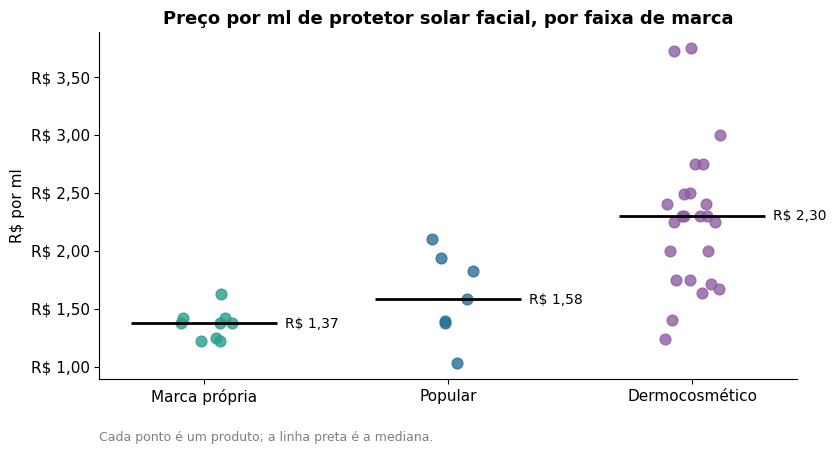

Dermocosmético custa 1.5x o preço por ml do popular (mediana).


In [6]:
ordem = (df.groupby("faixa")["preco_ml"].median().sort_values().index.tolist())

fig, ax = plt.subplots(figsize=(9, 4.5))
rng = np.random.default_rng(42)
for i, faixa in enumerate(ordem):
    sub = df[df["faixa"] == faixa]
    x = i + rng.uniform(-0.12, 0.12, len(sub))
    ax.scatter(x, sub["preco_ml"], s=60, alpha=0.8, color=CORES_FAIXA.get(faixa, "gray"))
    med = sub["preco_ml"].median()
    ax.hlines(med, i - 0.3, i + 0.3, color="black", lw=2)
    ax.text(i + 0.33, med, reais(med), va="center", fontsize=10)
ax.set_xticks(range(len(ordem)), ordem)
ax.set_title("Preço por ml de protetor solar facial, por faixa de marca")
ax.set_ylabel("R$ por ml")
eixo_reais(ax, casas=2)
ax.text(0, -0.18, "Cada ponto é um produto; a linha preta é a mediana.",
        transform=ax.transAxes, fontsize=9, color="gray")
salvar(fig, "01_preco_ml_por_faixa")
plt.show()

razao = df.groupby("faixa")["preco_ml"].median()
if {"Popular", "Dermocosmético"} <= set(razao.index):
    print(f"Dermocosmético custa {razao['Dermocosmético'] / razao['Popular']:.1f}x o preço por ml do popular (mediana).")

### 4.2 Custo mensal do uso diário e peso no salário mínimo
Custo mensal = preço por ml × ml por aplicação × 30 dias.

In [7]:
for nome, dose in DOSES_ML.items():
    df[f"custo_mes | {nome}"] = df["preco_ml"] * dose * DIAS_MES

col_rec = [c for c in df.columns if c.startswith("custo_mes | Recomendado")][0]
col_eco = [c for c in df.columns if c.startswith("custo_mes | Econômico")][0]
df["pct_sm_recomendado"] = df[col_rec] / SALARIO_MINIMO
df["pct_sm_economico"] = df[col_eco] / SALARIO_MINIMO
dose_rec = list(DOSES_ML.values())[0]
df["dias_embalagem_recomendado"] = df["quantidade"] / dose_rec

resumo_custo = df.groupby("faixa").agg(
    custo_mes_recomendado=(col_rec, "median"),
    custo_mes_economico=(col_eco, "median"),
    pct_sm_recomendado=("pct_sm_recomendado", "median"),
    dias_que_dura_a_embalagem=("dias_embalagem_recomendado", "median"),
).sort_values("custo_mes_recomendado")
resumo_custo.style.format({
    "custo_mes_recomendado": lambda v: reais(v), "custo_mes_economico": lambda v: reais(v),
    "pct_sm_recomendado": "{:.1%}", "dias_que_dura_a_embalagem": "{:.0f} dias",
})

,custo_mes_recomendado,custo_mes_economico,pct_sm_recomendado,dias_que_dura_a_embalagem
faixa,,,,
Marca própria,"R$ 205,88","R$ 102,94",12.7%,8 dias
Popular,"R$ 236,97","R$ 118,48",14.6%,10 dias
Dermocosmético,"R$ 344,70","R$ 172,35",21.3%,8 dias


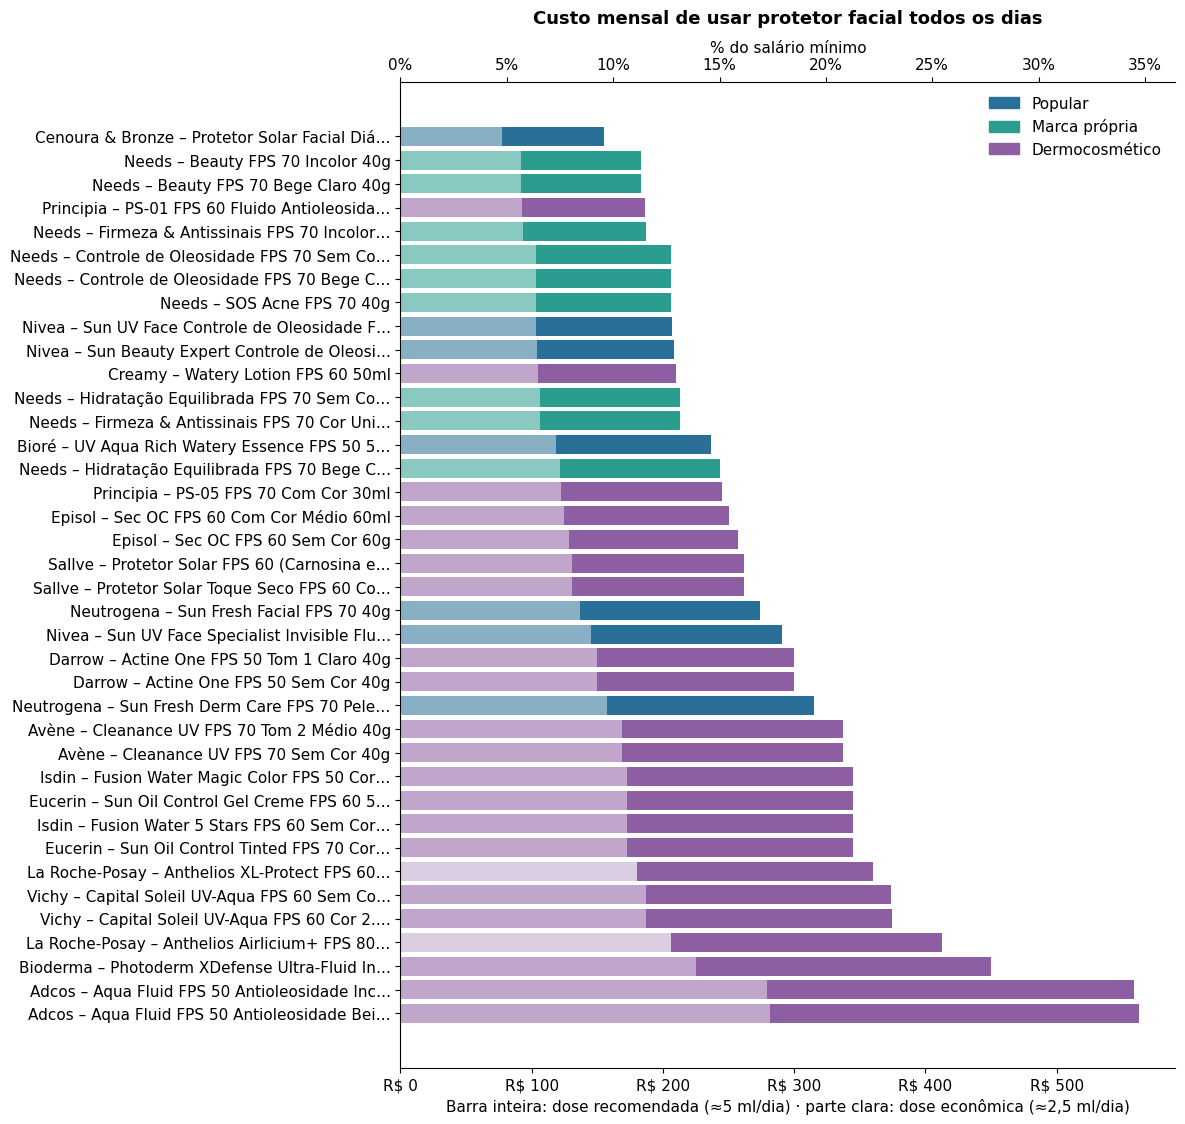

In [8]:
ordenado = df.sort_values(col_rec)
def rotulo(marca, produto, limite=45):
    marca = re.sub(r"\s*\(.*\)", "", marca)          # tira "(Raia/Drogasil)", "(Mantecorp)"
    if produto.lower().startswith(marca.lower()):   # evita "Needs – Needs ..."
        produto = produto[len(marca):].strip()
    texto = f"{marca} – {produto}"
    return texto if len(texto) <= limite else texto[:limite - 1].rstrip() + "…"

rotulos = [rotulo(m, p) for m, p in zip(ordenado["marca"], ordenado["produto"])]

fig, ax = plt.subplots(figsize=(10, max(4, 0.32 * len(ordenado))))
ax.barh(rotulos, ordenado[col_rec],
        color=[CORES_FAIXA.get(f, "gray") for f in ordenado["faixa"]])
ax.barh(rotulos, ordenado[col_eco], color="white", alpha=0.45)
ax.invert_yaxis()
eixo_reais(ax, eixo="x")
ax.set_title("Custo mensal de usar protetor facial todos os dias", pad=12)
ax.set_xlabel("Barra inteira: dose recomendada (≈5 ml/dia) · parte clara: dose econômica (≈2,5 ml/dia)")

ax2 = ax.secondary_xaxis("top", functions=(lambda x: x / SALARIO_MINIMO, lambda p: p * SALARIO_MINIMO))
ax2.xaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax2.set_xlabel("% do salário mínimo")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for f, c in CORES_FAIXA.items() if f in df["faixa"].values]
ax.legend(handles, [f for f in CORES_FAIXA if f in df["faixa"].values], frameon=False,
          loc="upper right")
salvar(fig, "02_custo_mensal_produtos")
plt.show()

In [9]:
mais_barato = df.loc[df[col_rec].idxmin()]
mais_caro = df.loc[df[col_rec].idxmax()]
print(f"Mais barato por mês: {mais_barato['marca']} – {mais_barato['produto']}: "
      f"{reais(mais_barato[col_rec])} ({mais_barato['pct_sm_recomendado']:.1%} do salário mínimo)")
print(f"Mais caro por mês:   {mais_caro['marca']} – {mais_caro['produto']}: "
      f"{reais(mais_caro[col_rec])} ({mais_caro['pct_sm_recomendado']:.1%} do salário mínimo)")
print(f"\nNa dose recomendada, uma embalagem dura {df['dias_embalagem_recomendado'].median():.0f} dias (mediana).")
for limite in [0.02, 0.05]:
    n = (df["pct_sm_recomendado"] <= limite).sum()
    print(f"Produtos que custam até {limite:.0%} do salário mínimo por mês: {n} de {len(df)}")

Mais barato por mês: Cenoura & Bronze – Protetor Solar Facial Diário FPS 70 Toque Seco 50g: R$ 154,77 (9.5% do salário mínimo)
Mais caro por mês:   Adcos – Aqua Fluid FPS 50 Antioleosidade Beige 40ml: R$ 562,46 (34.7% do salário mínimo)

Na dose recomendada, uma embalagem dura 8 dias (mediana).
Produtos que custam até 2% do salário mínimo por mês: 0 de 40
Produtos que custam até 5% do salário mínimo por mês: 0 de 40


---
## 5. Tipos de pele e acabamento

O clima quente e úmido favorece a oleosidade, e quem tem pele oleosa costuma procurar protetores de toque seco. Será que essa opção é mais cara?

In [10]:
por_pele = df.groupby("tipo_pele").agg(
    produtos=("produto", "count"),
    preco_ml_mediano=("preco_ml", "median"),
    custo_mes_mediano=(col_rec, "median"),
    opcoes_populares_ou_proprias=("faixa", lambda s: s.isin(["Popular", "Marca própria"]).sum()),
).sort_values("produtos", ascending=False)
por_pele

,produtos,preco_ml_mediano,custo_mes_mediano,opcoes_populares_ou_proprias
tipo_pele,,,,
Oleosa,22,2.00,299.96,7
Todos os tipos,16,1.79,267.92,7
Não informado,2,1.22,183.38,2


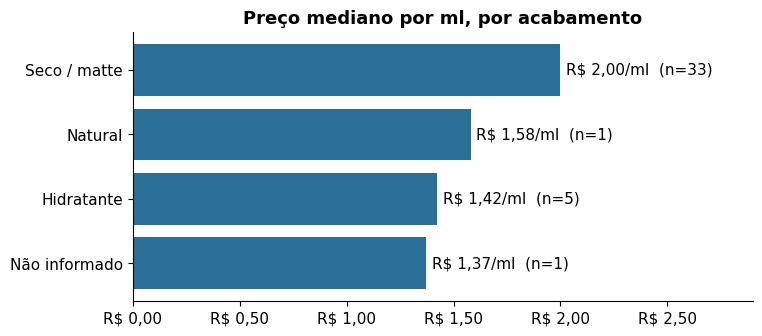

In [11]:
por_acab = df.groupby("acabamento").agg(
    produtos=("produto", "count"),
    preco_ml_mediano=("preco_ml", "median"),
    custo_mes_mediano=(col_rec, "median"),
).sort_values("preco_ml_mediano")

fig, ax = plt.subplots(figsize=(8, 3.5))
barras = ax.barh(por_acab.index, por_acab["preco_ml_mediano"], color=COR_NEUTRA)
ax.bar_label(barras, labels=[f"{reais(v)}/ml  (n={n})" for v, n in zip(por_acab["preco_ml_mediano"], por_acab["produtos"])], padding=4)
ax.set_title("Preço mediano por ml, por acabamento")
eixo_reais(ax, eixo="x", casas=2)
ax.set_xlim(0, por_acab["preco_ml_mediano"].max() * 1.45)
salvar(fig, "03_preco_por_acabamento")
plt.show()

In [12]:
# Opções mais baratas para pele oleosa (indicadas para oleosa/mista/acneica ou com toque seco)
oleosa = df[df["tipo_pele"].isin(["Oleosa", "Mista", "Acneica"]) | (df["acabamento"] == "Seco / matte")]
print(f"Produtos indicados para pele oleosa ou com toque seco: {len(oleosa)} de {len(df)}")
oleosa.sort_values(col_rec)[["marca", "produto", "faixa", "fps", "preco", "quantidade", col_rec]].head(5)

Produtos indicados para pele oleosa ou com toque seco: 34 de 40


,marca,produto,faixa,fps,preco,quantidade,custo_mes | Recomendado (1 colher de chá ≈ 5 ml)
13,Cenoura & Bronze,Protetor Solar Facial Diário FPS 70 Toque Seco...,Popular,70,51.59,50,154.77
16,Principia,PS-01 FPS 60 Fluido Antioleosidade 40ml,Dermocosmético,60,49.59,40,185.96
21,Needs (Raia/Drogasil),Needs Firmeza & Antissinais FPS 70 Incolor 40g,Marca própria,70,49.90,40,187.13
18,Needs (Raia/Drogasil),Needs Controle de Oleosidade FPS 70 Sem Cor 40g,Marca própria,70,54.90,40,205.88
22,Needs (Raia/Drogasil),Needs SOS Acne FPS 70 40g,Marca própria,70,54.90,40,205.88


### 5.1 FPS mais alto custa mais?

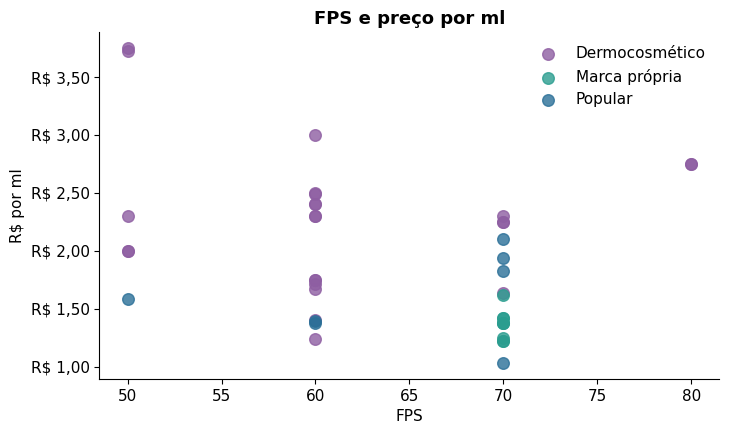

Correlação de Spearman entre FPS e preço por ml: -0.28


In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for faixa, sub in df.groupby("faixa"):
    ax.scatter(sub["fps"], sub["preco_ml"], s=70, alpha=0.8,
               color=CORES_FAIXA.get(faixa, "gray"), label=faixa)
ax.set_xlabel("FPS")
ax.set_ylabel("R$ por ml")
eixo_reais(ax, casas=2)
ax.set_title("FPS e preço por ml")
ax.legend(frameon=False)
salvar(fig, "04_fps_vs_preco")
plt.show()

print("Correlação de Spearman entre FPS e preço por ml:",
      round(df["fps"].corr(df["preco_ml"], method="spearman"), 2))

### 5.2 Os extras deixam o protetor mais caro?

Muitos protetores destacam ativos de skincare na embalagem e na página do produto, como niacinamida, vitamina C e ácido hialurônico. Aqui comparo o preço de quem **anuncia** e de quem não anuncia cada extra.

**Dois cuidados importantes:**
- O critério é o ativo **estar na lista de ingredientes (INCI) do site oficial da marca**. Quando o site oficial não mostra a lista, a coluna Observações da planilha diz qual fonte foi usada (para a Needs, a página da própria Drogasil). Estar na lista não diz **quanto** tem: por isso esta análise fala de preço e de posicionamento, não de eficácia.
- Dermocosméticos costumam ter mais ativos **e** ser mais caros. Para não confundir "ter niacinamida" com "ser dermocosmético", comparo cada produto com a **mediana da sua própria faixa**: um preço relativo de 1,2 quer dizer 20% acima do típico da faixa.

**Como comparo:** a diferença é a razão entre as **médias geométricas** do preço relativo de quem tem e de quem não tem o extra (a média geométrica é a adequada para razões de preço). Usei a média e não a mediana porque várias versões com e sem cor têm o mesmo preço: com esses empates, as medianas dos dois grupos caem no mesmo produto e a diferença sai artificialmente em 0%. Para saber se a diferença pode ser só acaso, uso o **teste de Mann-Whitney**: p abaixo de 0,05 indica diferença estatisticamente significativa.

In [14]:
# só os quatro ativos da coleta; "Outros ativos" mistura nomes de tecnologia de marketing
df["tem_ativo_extra"] = df[list(ATIVOS)].any(axis=1)
df["seco_matte"] = df["acabamento"] == "Seco / matte"
df["tem_cor"] = df["com_cor"] == "Sim"
df["ppd_informado"] = df["ppd"].notna()
df["preco_rel_faixa"] = df["preco_ml"] / df.groupby("faixa")["preco_ml"].transform("median")
df["log_rel_faixa"] = np.log(df["preco_rel_faixa"])
from scipy.stats import mannwhitneyu

EXTRAS = {**ATIVOS, "tem_ativo_extra": "Qualquer ativo extra", "tem_cor": "Com cor",
          "seco_matte": "Toque seco / matte", "ppd_informado": "Informa proteção UVA (PPD)"}
MIN_N = 3  # mínimo de produtos em cada grupo para a comparação valer

linhas = []
for col, nome in EXTRAS.items():
    com, sem = df[df[col]], df[~df[col]]
    linhas.append({
        "extra": nome, "produtos_com": len(com), "produtos_sem": len(sem),
        "preco_ml_com": com["preco_ml"].median(), "preco_ml_sem": sem["preco_ml"].median(),
        # razão das médias geométricas do preço relativo à faixa
        "dif_dentro_da_faixa": np.exp(com["log_rel_faixa"].mean() - sem["log_rel_faixa"].mean()) - 1
                               if len(com) and len(sem) else np.nan,
        "p_valor": mannwhitneyu(com["log_rel_faixa"], sem["log_rel_faixa"]).pvalue
                   if len(com) and len(sem) else np.nan,
        "amostra_ok": len(com) >= MIN_N and len(sem) >= MIN_N,
    })
extras = pd.DataFrame(linhas).set_index("extra")
extras.style.format({"preco_ml_com": lambda v: reais(v) if pd.notna(v) else "–",
                     "preco_ml_sem": lambda v: reais(v) if pd.notna(v) else "–",
                     "dif_dentro_da_faixa": "{:+.0%}", "p_valor": "{:.2f}"}, na_rep="–")

,produtos_com,produtos_sem,preco_ml_com,preco_ml_sem,dif_dentro_da_faixa,p_valor,amostra_ok
extra,,,,,,,
Niacinamida,14,26,"R$ 1,40","R$ 2,05",+3%,0.90,True
Vitamina C,2,38,"R$ 2,49","R$ 1,75",+13%,0.23,False
Ácido hialurônico,15,25,"R$ 1,72","R$ 1,82",+10%,0.59,True
Vitamina E,36,4,"R$ 1,79","R$ 1,96",+6%,0.95,True
Qualquer ativo extra,37,3,"R$ 1,75","R$ 2,30",+16%,0.47,True
Com cor,17,23,"R$ 2,00","R$ 1,75",+5%,0.66,True
Toque seco / matte,33,7,"R$ 2,00","R$ 1,42",+2%,0.78,True
Informa proteção UVA (PPD),9,31,"R$ 2,40","R$ 1,72",+7%,0.29,True


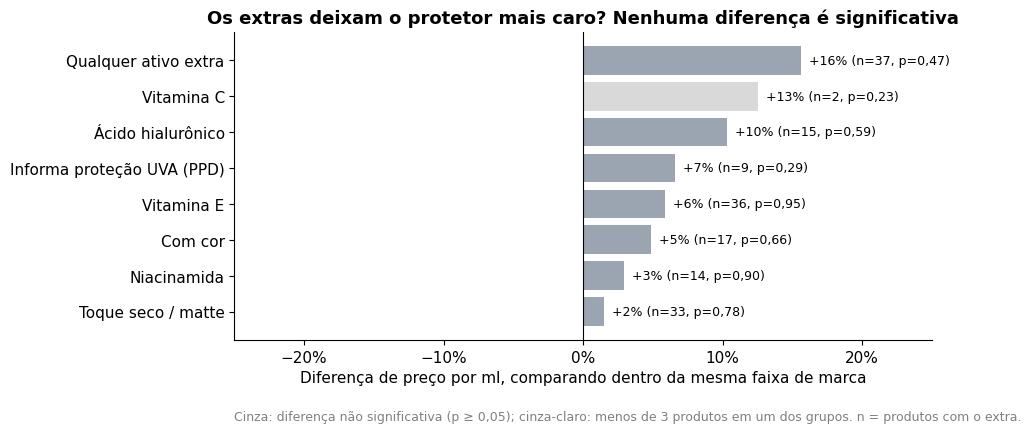

In [15]:
graf = extras.dropna(subset=["dif_dentro_da_faixa"]).sort_values("dif_dentro_da_faixa")

fig, ax = plt.subplots(figsize=(9, max(3.5, 0.5 * len(graf))))
signif = graf["amostra_ok"] & (graf["p_valor"] < 0.05)
cores = [(COR_DESTAQUE if v > 0 else COR_NEUTRA) if s else ("#9aa5b1" if ok else "#d9d9d9")
         for v, s, ok in zip(graf["dif_dentro_da_faixa"], signif, graf["amostra_ok"])]
ax.barh(graf.index, graf["dif_dentro_da_faixa"], color=cores)
ax.axvline(0, color="black", lw=0.8)
for i, (v, n, p) in enumerate(zip(graf["dif_dentro_da_faixa"], graf["produtos_com"], graf["p_valor"])):
    ax.text(v, i, f"  {v:+.0%} (n={n}, p={p:.2f})  ".replace(".", ","), va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
lim = graf["dif_dentro_da_faixa"].abs().max() * 1.6
ax.set_xlim(-lim, lim)
ax.set_title("Os extras deixam o protetor mais caro? Nenhuma diferença é significativa")
ax.set_xlabel("Diferença de preço por ml, comparando dentro da mesma faixa de marca")
ax.text(0, -0.26, f"Cinza: diferença não significativa (p ≥ 0,05); cinza-claro: menos de {MIN_N} produtos em um dos grupos. "
        "n = produtos com o extra.", transform=ax.transAxes, fontsize=9, color="gray")
salvar(fig, "05_extras_e_preco")
plt.show()

In [16]:
# Quem coloca mais ativos: % de produtos com cada ativo, por faixa
presenca = df.groupby("faixa")[list(ATIVOS) + ["tem_ativo_extra"]].mean()
presenca = presenca.rename(columns={**ATIVOS, "tem_ativo_extra": "Qualquer ativo extra"})
presenca.style.format("{:.0%}").background_gradient(cmap="Oranges", axis=None)

,Niacinamida,Vitamina C,Ácido hialurônico,Vitamina E,Qualquer ativo extra
faixa,,,,,
Dermocosmético,25%,8%,38%,88%,88%
Marca própria,78%,0%,56%,89%,100%
Popular,14%,0%,14%,100%,100%


In [17]:
# Tipo de filtro
df.groupby("tipo_filtro").agg(
    produtos=("produto", "count"),
    preco_ml_mediano=("preco_ml", "median"),
    custo_mes_mediano=(col_rec, "median"),
)

,produtos,preco_ml_mediano,custo_mes_mediano
tipo_filtro,,,
Misto,9,2.40,359.96
Não informado,3,1.62,243.38
Químico,28,1.69,253.72


#### Filtro mineral encarece?

Os filtros **mistos** combinam filtros químicos com um filtro mineral (dióxido de titânio), que costuma ser mais caro e deixa a textura mais difícil de formular. Como a maioria dos mistos é dermocosmética, comparo de novo **dentro da mesma faixa de marca**, com a mesma média geométrica e o mesmo teste de Mann-Whitney usados para os extras.

**Cuidado na leitura:** os 9 produtos mistos vêm de só 5 linhas de 4 marcas, e as versões com e sem cor da mesma linha contam como dois produtos. O teste supõe produtos independentes, então o p-valor sai mais otimista do que deveria. É um indício, não uma conclusão.

In [18]:
com_filtro = df[df["tipo_filtro"].isin(["Misto", "Químico"])]
misto = com_filtro[com_filtro["tipo_filtro"] == "Misto"]
quimico = com_filtro[com_filtro["tipo_filtro"] == "Químico"]

print(pd.crosstab(com_filtro["tipo_filtro"], com_filtro["faixa"]), "\n")
dif_filtro = np.exp(misto["log_rel_faixa"].mean() - quimico["log_rel_faixa"].mean()) - 1
p_filtro = mannwhitneyu(misto["log_rel_faixa"], quimico["log_rel_faixa"]).pvalue
print(f"Preço por ml mediano: misto {reais(misto['preco_ml'].median())} | químico {reais(quimico['preco_ml'].median())}")
print(f"Dentro da mesma faixa, o misto custa {dif_filtro:+.0%} por ml (Mann-Whitney p = {p_filtro:.3f})")
print(f"Marcas entre os mistos: {misto['marca'].nunique()}")
misto[["marca", "produto", "faixa", "preco_ml"]]


faixa        Dermocosmético  Marca própria  Popular
tipo_filtro                                        
Misto                     6              0        3
Químico                  17              7        4 

Preço por ml mediano: misto R$ 2,40 | químico R$ 1,69
Dentro da mesma faixa, o misto custa +28% por ml (Mann-Whitney p = 0.002)
Marcas entre os mistos: 4


,marca,produto,faixa,preco_ml
0,La Roche-Posay,Anthelios Airlicium+ FPS 80 Antioleosidade Sem...,Dermocosmético,2.75
1,La Roche-Posay,Anthelios XL-Protect FPS 60 Sem Cor 40g,Dermocosmético,2.40
9,Adcos,Aqua Fluid FPS 50 Antioleosidade Incolor 40ml,Dermocosmético,3.73
12,Neutrogena,Sun Fresh Facial FPS 70 40g,Popular,1.82
13,Cenoura & Bronze,Protetor Solar Facial Diário FPS 70 Toque Seco...,Popular,1.03
23,La Roche-Posay,Anthelios Airlicium+ FPS 80 Antioleosidade Cor...,Dermocosmético,2.75
24,La Roche-Posay,Anthelios XL-Protect FPS 60 Cor Clara 40g,Dermocosmético,2.40
31,Adcos,Aqua Fluid FPS 50 Antioleosidade Beige 40ml,Dermocosmético,3.75
33,Neutrogena,Sun Fresh Derm Care FPS 70 Pele Morena 40g,Popular,2.10


### 5.3 Quanto de ativo tem? A ordem do rótulo

A seção anterior só olha se o ativo **aparece** na lista. Dá para ir um pouco além usando duas regras da rotulagem de cosméticos:

- Os ingredientes acima de 1% vêm em **ordem decrescente** de concentração. Os que estão abaixo de 1% podem vir **em qualquer ordem**, depois deles.
- O **fenoxietanol**, conservante mais comum dessas fórmulas, tem **limite de 1%**.

Logo, um ativo que aparece **depois** do fenoxietanol está em **no máximo 1%**. O contrário não vale: aparecer antes não prova que a dose é alta, porque abaixo de 1% a ordem é livre. Quando a fórmula não usa fenoxietanol, a regra não se aplica. (Ideia sugerida pelo Henrique.)

In [19]:
import re

def separar_inci(texto):
    """Quebra a lista de ingredientes nos separadores usados pelas marcas (; • , ou ponto)."""
    s = str(texto).strip().rstrip(".")
    if "•" in s:
        partes = s.split("•")
    elif ";" in s:
        partes = s.split(";")
    elif re.search(r"\.\s+[A-Z]", s) and s.count(",") < 5:
        partes = re.split(r"\.\s+", s)
    else:
        partes = re.split(r",\s*(?![^()]*\))", s)
    return [p.strip() for p in partes if p.strip()]

PADROES_ATIVO = {"niacinamida": r"niacinamid|nicotinamid", "vitamina_c": r"ascorb",
                 "acido_hialuronico": r"hyalur|hialur", "vitamina_e": r"tocopher|tocofer"}
CONSERVANTE = r"phenoxyethanol|fenoxietanol"

def posicao(lista, padrao):
    return next((i + 1 for i, x in enumerate(lista) if re.search(padrao, x, re.I)), None)

lista_ok = df["inci"].notna() & ~df["fonte_inci"].astype(str).str.contains("SUSPEITA|Pendente|PARCIAL", case=False)
df["n_ingredientes"] = np.where(lista_ok, df["inci"].map(lambda t: len(separar_inci(t)) if pd.notna(t) else np.nan), np.nan)

linhas = []
for _, r in df[lista_ok].iterrows():
    ing = separar_inci(r["inci"])
    pos_cons = posicao(ing, CONSERVANTE)
    for col, padrao in PADROES_ATIVO.items():
        pos = posicao(ing, padrao)
        if pos is None:
            continue
        if pos_cons is None:
            situacao = "Sem fenoxietanol (regra não se aplica)"
        elif pos > pos_cons:
            situacao = "Depois do conservante: no máximo 1%"
        else:
            situacao = "Antes do conservante"
        linhas.append({"marca": r["marca"], "produto": r["produto"], "faixa": r["faixa"],
                       "ativo": ATIVOS[col], "posicao_ativo": pos, "posicao_conservante": pos_cons,
                       "total_ingredientes": len(ing), "situacao": situacao, "preco_ml": r["preco_ml"]})
ordem_ativos = pd.DataFrame(linhas)
print(f"Produtos com lista de ingredientes confiável: {lista_ok.sum()} de {len(df)}")
pd.crosstab(ordem_ativos["ativo"], ordem_ativos["situacao"], margins=True, margins_name="Total")

Produtos com lista de ingredientes confiável: 28 de 40


situacao,Antes do conservante,Depois do conservante: no máximo 1%,Sem fenoxietanol (regra não se aplica),Total
ativo,,,,
Niacinamida,6,1,0,7
Vitamina C,0,0,1,1
Vitamina E,9,7,9,25
Ácido hialurônico,0,5,5,10
Total,15,13,15,43


In [20]:
# Detalhe: onde cada ativo aparece em cada produto
(ordem_ativos.sort_values(["ativo", "situacao", "preco_ml"])
 [["ativo", "marca", "produto", "faixa", "posicao_ativo", "posicao_conservante", "total_ingredientes", "situacao"]])

,ativo,marca,produto,faixa,posicao_ativo,posicao_conservante,total_ingredientes,situacao
24,Niacinamida,Principia,PS-01 FPS 60 Fluido Antioleosidade 40ml,Dermocosmético,26,28.00,29,Antes do conservante
26,Niacinamida,Needs (Raia/Drogasil),Needs Controle de Oleosidade FPS 70 Sem Cor 40g,Marca própria,11,25.00,35,Antes do conservante
41,Niacinamida,Principia,PS-05 FPS 70 Com Cor 30ml,Dermocosmético,32,34.00,35,Antes do conservante
17,Niacinamida,Nivea,Sun UV Face Specialist Invisible Fluido FPS 70...,Popular,15,28.00,30,Antes do conservante
33,Niacinamida,La Roche-Posay,Anthelios Airlicium+ FPS 80 Antioleosidade Cor...,Dermocosmético,11,46.00,51,Antes do conservante
13,Niacinamida,Adcos,Aqua Fluid FPS 50 Antioleosidade Incolor 40ml,Dermocosmético,8,15.00,43,Antes do conservante
29,Niacinamida,Needs (Raia/Drogasil),Needs Beauty FPS 70 Incolor 40g,Marca própria,27,19.00,34,Depois do conservante: no máximo 1%
6,Vitamina C,Vichy,Capital Soleil UV-Aqua FPS 60 Sem Cor 40g,Dermocosmético,23,NaN,33,Sem fenoxietanol (regra não se aplica)
25,Vitamina E,Principia,PS-01 FPS 60 Fluido Antioleosidade 40ml,Dermocosmético,20,28.00,29,Antes do conservante
28,Vitamina E,Needs (Raia/Drogasil),Needs Controle de Oleosidade FPS 70 Sem Cor 40g,Marca própria,21,25.00,35,Antes do conservante


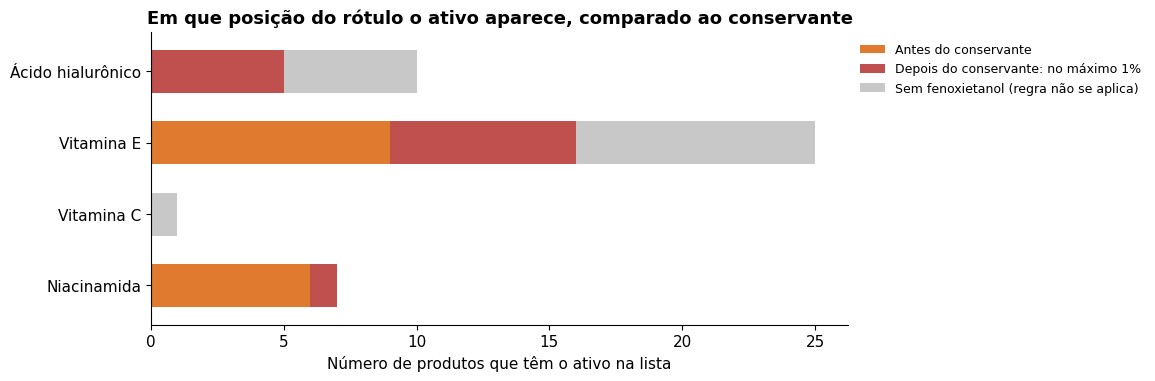

In [21]:
tab = pd.crosstab(ordem_ativos["ativo"], ordem_ativos["situacao"])
cores_sit = {"Antes do conservante": COR_DESTAQUE, "Depois do conservante: no máximo 1%": "#c0504d",
             "Sem fenoxietanol (regra não se aplica)": "#c8c8c8"}
tab = tab[[c for c in cores_sit if c in tab.columns]]
fig, ax = plt.subplots(figsize=(9, 3.8))
tab.plot.barh(stacked=True, ax=ax, color=[cores_sit[c] for c in tab.columns], width=0.6)
ax.set_xlabel("Número de produtos que têm o ativo na lista")
ax.set_ylabel("")
ax.set_title("Em que posição do rótulo o ativo aparece, comparado ao conservante")
ax.legend(frameon=False, bbox_to_anchor=(1, 1), loc="upper left", fontsize=9)
salvar(fig, "05b_ativos_vs_conservante")
plt.show()

### 5.4 Com cor custa mais?

Para cada produto que tem as duas versões na coleta, comparo o preço cheio por ml da versão **com cor** com o da versão **sem cor** da mesma linha. Ficam de fora a Sallve e a Principia, cuja versão com cor é de outra linha.

In [22]:
def chave_linha(nome):
    nome = re.sub(r"(?i)\b(sem cor|incolor|com cor|cor\s*[\w.]+|tom\s*\d\s*\w*|bege\s*\w+|beige|pele morena|cor universal|médio|tinted)\b", "", nome)
    nome = re.sub(r"\d+\s*(ml|g)\b", "", nome, flags=re.I)
    return re.sub(r"\s+", " ", nome).strip().lower()

pares = []
for marca, sub in df.groupby("marca"):
    sem = sub[sub["com_cor"] == "Não"]
    com = sub[sub["com_cor"] == "Sim"]
    for _, c in com.iterrows():
        if "Linha diferente" in str(c["obs"]):  # Sallve e Principia: com cor de outra linha
            continue
        # a versão sem cor da mesma linha é a que tem mais palavras em comum no nome
        if sem.empty:
            continue
        pal_c = set(chave_linha(c["produto"]).split())
        comum = sem["produto"].map(lambda p: len(pal_c & set(chave_linha(p).split())))
        s = sem.loc[comum.idxmax()]
        if comum.max() < 2:
            continue
        pares.append({"marca": marca, "sem_cor": s["produto"], "com_cor": c["produto"],
                      "preco_ml_sem": s["preco_ml"], "preco_ml_com": c["preco_ml"],
                      "dif": c["preco_ml"] / s["preco_ml"] - 1})
pares = pd.DataFrame(pares)
print(f"Pares comparados: {len(pares)} | diferença mediana: {pares['dif'].median():+.0%}")
pares.style.format({"preco_ml_sem": reais, "preco_ml_com": reais, "dif": "{:+.0%}"})

Pares comparados: 15 | diferença mediana: +0%


,marca,sem_cor,com_cor,preco_ml_sem,preco_ml_com,dif
0,Adcos,Aqua Fluid FPS 50 Antioleosidade Incolor 40ml,Aqua Fluid FPS 50 Antioleosidade Beige 40ml,"R$ 3,73","R$ 3,75",+1%
1,Avène,Cleanance UV FPS 70 Sem Cor 40g,Cleanance UV FPS 70 Tom 2 Médio 40g,"R$ 2,25","R$ 2,25",+0%
2,Darrow,Actine One FPS 50 Sem Cor 40g,Actine One FPS 50 Tom 1 Claro 40g,"R$ 2,00","R$ 2,00",+0%
3,Episol (Mantecorp),Episol Sec OC FPS 60 Sem Cor 60g,Episol Sec OC FPS 60 Com Cor Médio 60ml,"R$ 1,72","R$ 1,67",-3%
4,Eucerin,Sun Oil Control Gel Creme FPS 60 50ml,Sun Oil Control Tinted FPS 70 Cor Média 50ml,"R$ 2,30","R$ 2,30",+0%
5,Isdin,Fusion Water 5 Stars FPS 60 Sem Cor 50ml,Fusion Water Magic Color FPS 50 Cor Média 50ml,"R$ 2,30","R$ 2,30",-0%
6,La Roche-Posay,Anthelios Airlicium+ FPS 80 Antioleosidade Sem Cor 40g,Anthelios Airlicium+ FPS 80 Antioleosidade Cor 2.0 40g,"R$ 2,75","R$ 2,75",+0%
7,La Roche-Posay,Anthelios XL-Protect FPS 60 Sem Cor 40g,Anthelios XL-Protect FPS 60 Cor Clara 40g,"R$ 2,40","R$ 2,40",+0%
8,Needs (Raia/Drogasil),Needs Controle de Oleosidade FPS 70 Sem Cor 40g,Needs Controle de Oleosidade FPS 70 Bege Claro 40g,"R$ 1,37","R$ 1,37",+0%
9,Needs (Raia/Drogasil),Needs Beauty FPS 70 Incolor 40g,Needs Beauty FPS 70 Bege Claro 40g,"R$ 1,22","R$ 1,22",+0%


---
## 6. Os produtos para pele ficaram mais caros?

O IPCA, a inflação oficial do IBGE, tem um subitem chamado **"Produto para pele"**. Comparo a alta acumulada dele com a do índice geral e com a do salário mínimo.

Os dados vêm da API do SIDRA (IBGE). Na primeira vez o notebook baixa e salva uma cópia em `data/`, e depois usa essa cópia. Uso duas tabelas, porque o IBGE mudou a cesta de produtos em 2020:
- **Tabela 1419:** janeiro de 2012 a dezembro de 2019
- **Tabela 7060:** janeiro de 2020 em diante

In [23]:
import urllib.request

def baixar_sidra(tabela):
    """Baixa a variação mensal (variável 63) de todos os subitens do IPCA, Brasil."""
    url = f"https://apisidra.ibge.gov.br/values/t/{tabela}/n1/all/v/63/p/all/c315/all"
    with urllib.request.urlopen(url, timeout=120) as resp:
        return json.loads(resp.read().decode("utf-8"))


def ler_sidra(dados):
    """Transforma a resposta da API em uma tabela com mês, categoria e variação.
    A primeira linha da resposta traz os nomes das colunas."""
    tab = pd.DataFrame(dados[1:])
    # coluna do mês: códigos no formato AAAAMM
    col_mes = next(c for c in tab.columns if c.endswith("C")
                   and tab[c].astype(str).str.fullmatch(r"(19|20)\d{4}").all())
    # coluna da categoria: a que contém "Índice geral"
    col_cat = next(c for c in tab.columns if c.endswith("N")
                   and tab[c].astype(str).str.contains("Índice geral").any())
    return pd.DataFrame({
        "mes": pd.PeriodIndex(tab[col_mes].astype(str), freq="M"),
        "categoria": (tab[col_cat].astype(str).str.replace(r"^\d+\.", "", regex=True)
                      # o nome do subitem pode variar um pouco entre as tabelas
                      .str.replace(r"(?i)^produtos? para (a )?pele$", "Produto para pele", regex=True)),
        "variacao": pd.to_numeric(tab["V"], errors="coerce"),
    })


def ipca(tabela):
    cache = DATA_DIR / f"ipca_tabela_{tabela}.csv"
    if cache.exists():
        t = pd.read_csv(cache)
        t["mes"] = pd.PeriodIndex(t["mes"], freq="M")
        return t
    t = ler_sidra(baixar_sidra(tabela))
    t.to_csv(cache, index=False)
    return t


ipca_bruto = pd.concat([ipca(1419), ipca(7060)], ignore_index=True)
serie = (ipca_bruto[ipca_bruto["categoria"].isin(["Índice geral", "Produto para pele"])]
         .pivot_table(index="mes", columns="categoria", values="variacao")
         .sort_index())
faltando = serie.isna().sum()
print("Período:", serie.index.min(), "a", serie.index.max())
print("Meses sem valor (tratados como variação zero):", faltando.to_dict())
assert {"Índice geral", "Produto para pele"} <= set(serie.columns), "Subitem não encontrado: conferir nomes em ipca_bruto"
serie = serie.fillna(0)
serie.tail()

Período: 2012-01 a 2026-10
Meses sem valor (tratados como variação zero): {'Produto para pele': 0, 'Índice geral': 0}


categoria,Produto para pele,Índice geral
mes,,
2026-06,0.77,0.16
2026-07,2.25,0.07
2026-08,-0.74,-0.32
2026-09,-1.00,0.82
2026-10,-0.58,0.14


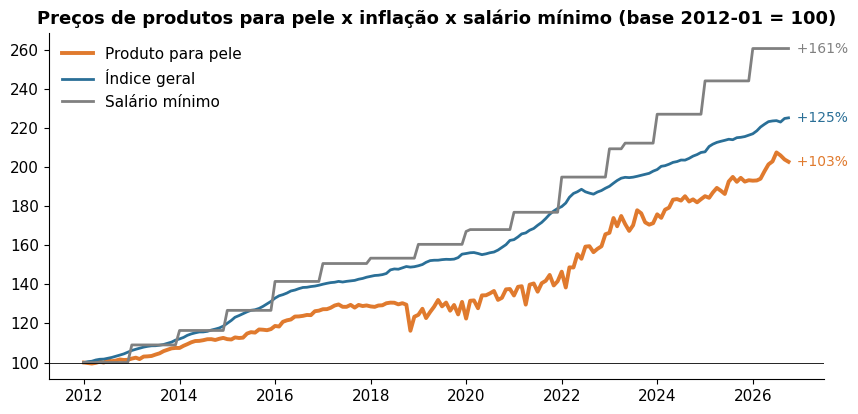

Alta acumulada desde 2012-01: produto para pele 103% | IPCA geral 125% | salário mínimo 161%


In [24]:
# Salário mínimo nacional (valores oficiais, por data de vigência)
SM_HISTORICO = {
    "2012-01": 622, "2013-01": 678, "2014-01": 724, "2015-01": 788, "2016-01": 880,
    "2017-01": 937, "2018-01": 954, "2019-01": 998, "2020-01": 1039, "2020-02": 1045,
    "2021-01": 1100, "2022-01": 1212, "2023-01": 1302, "2023-05": 1320, "2024-01": 1412,
    "2025-01": 1518, "2026-01": 1621,
}
sm = pd.Series(SM_HISTORICO, dtype=float)
sm.index = pd.PeriodIndex(sm.index, freq="M")
sm = sm.reindex(serie.index).ffill()

# Índice acumulado: base 100 no primeiro mês da série
acumulado = (1 + serie / 100).cumprod() * 100
acumulado = acumulado / acumulado.iloc[0] * 100
acumulado["Salário mínimo"] = sm / sm.iloc[0] * 100

fig, ax = plt.subplots()
estilos = {"Produto para pele": (COR_DESTAQUE, 2.8), "Índice geral": (COR_NEUTRA, 2),
           "Salário mínimo": ("gray", 2)}
for col, (cor, lw) in estilos.items():
    ax.plot(acumulado.index.to_timestamp(), acumulado[col], color=cor, lw=lw, label=col)
    ax.text(acumulado.index[-1].to_timestamp(), acumulado[col].iloc[-1],
            f"  {acumulado[col].iloc[-1] - 100:+.0f}%", color=cor, va="center", fontsize=10)
ax.axhline(100, color="black", lw=0.6)
ax.set_title(f"Preços de produtos para pele x inflação x salário mínimo (base {serie.index[0]} = 100)")
ax.legend(frameon=False)
salvar(fig, "06_ipca_produto_para_pele")
plt.show()

alta_pele = acumulado["Produto para pele"].iloc[-1] - 100
alta_geral = acumulado["Índice geral"].iloc[-1] - 100
alta_sm = acumulado["Salário mínimo"].iloc[-1] - 100
print(f"Alta acumulada desde {serie.index[0]}: produto para pele {alta_pele:.0f}% | "
      f"IPCA geral {alta_geral:.0f}% | salário mínimo {alta_sm:.0f}%")

---
## 7. Comportamento de busca (Google Trends)

O Google Trends não mostra o número de buscas. Ele mostra um **índice de 0 a 100**: 100 é o momento (ou o estado) de maior interesse no período, e o resto é proporcional a ele. Por isso, as comparações aqui são sempre relativas.

Dois arquivos baixados em trends.google.com.br (instruções no README):
- `trends_tempo.csv`: interesse ao longo dos últimos 5 anos, Brasil
- `trends_estados.csv`: interesse por estado nos últimos 12 meses

In [25]:
def ler_trends(caminho):
    """Lê um CSV exportado do Google Trends, pulando as linhas de cabeçalho
    que mudam conforme a versão do site."""
    linhas = Path(caminho).read_text(encoding="utf-8-sig").splitlines()
    inicio = next(i for i in range(len(linhas) - 1)
                  if "," in linhas[i] and "," in linhas[i + 1])
    from io import StringIO
    t = pd.read_csv(StringIO("\n".join(linhas[inicio:])))
    t.columns = [re.sub(r":\s*\(.*\)$", "", c).strip() for c in t.columns]
    for c in t.columns[1:]:
        t[c] = pd.to_numeric(t[c].astype(str).str.replace("<1", "0.5"), errors="coerce")
    return t


tempo = ler_trends(DATA_DIR / "trends_tempo.csv")
tempo = tempo.rename(columns={tempo.columns[0]: "data"})
tempo["data"] = pd.to_datetime(tempo["data"])
termos = list(tempo.columns[1:])
print("Termos:", termos)
print("Período:", tempo["data"].min().date(), "a", tempo["data"].max().date())

Termos: ['protetor solar facial', 'protetor solar pele oleosa']
Período: 2021-11-21 a 2026-11-22


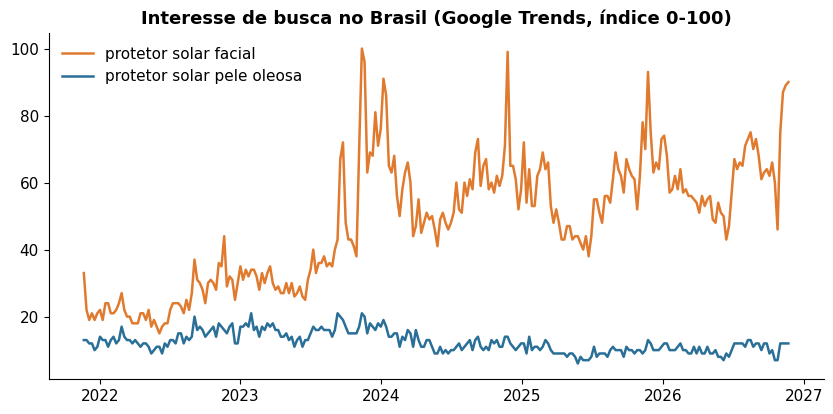

In [26]:
fig, ax = plt.subplots()
cores_termos = [COR_DESTAQUE, COR_NEUTRA, "#2a9d8f", "#8e5ea2", "gray"]
for termo, cor in zip(termos, cores_termos):
    ax.plot(tempo["data"], tempo[termo], lw=1.8, color=cor, label=termo)
ax.set_title("Interesse de busca no Brasil (Google Trends, índice 0-100)")
ax.legend(frameon=False)
salvar(fig, "07_trends_tempo")
plt.show()

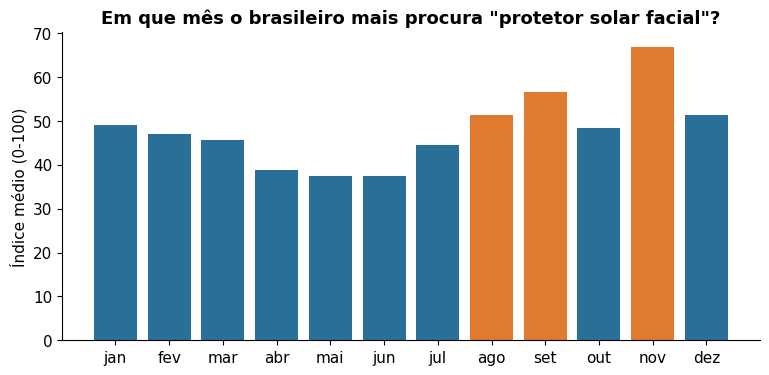

Mês de maior interesse: nov (67) | menor: mai (38) | o pico é 1.8x o vale


In [27]:
# Sazonalidade: média do índice em cada mês do ano
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
principal = termos[0]
sazonal = tempo.groupby(tempo["data"].dt.month)[principal].mean()

fig, ax = plt.subplots(figsize=(9, 4))
cores = [COR_DESTAQUE if v >= sazonal.quantile(0.75) else COR_NEUTRA for v in sazonal]
ax.bar([MESES[m - 1] for m in sazonal.index], sazonal.values, color=cores)
ax.set_title(f'Em que mês o brasileiro mais procura "{principal}"?')
ax.set_ylabel("Índice médio (0-100)")
salvar(fig, "08_trends_sazonalidade")
plt.show()

pico, vale = sazonal.idxmax(), sazonal.idxmin()
print(f"Mês de maior interesse: {MESES[pico-1]} ({sazonal.max():.0f}) | "
      f"menor: {MESES[vale-1]} ({sazonal.min():.0f}) | "
      f"o pico é {sazonal.max()/sazonal.min():.1f}x o vale")

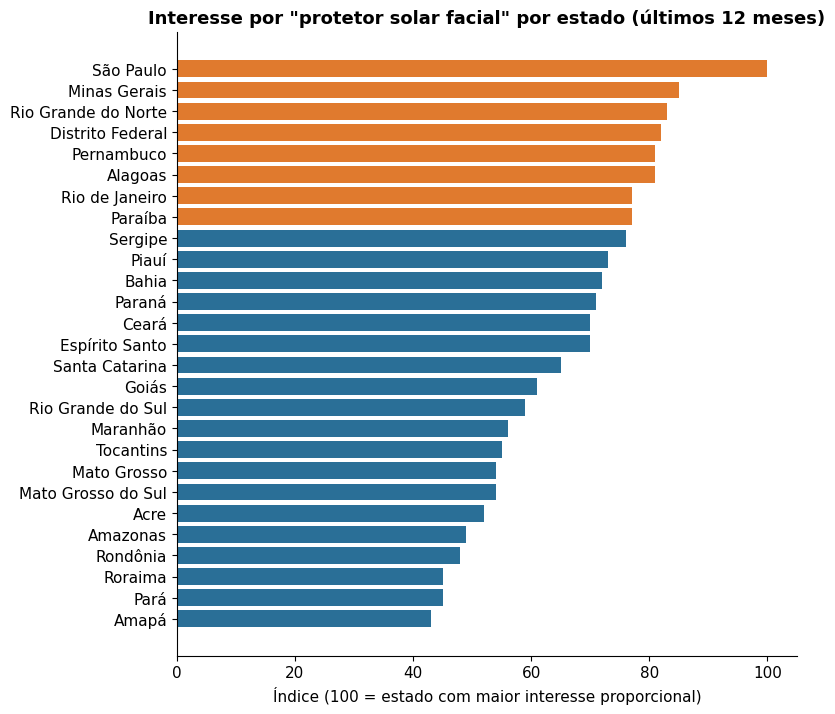

In [28]:
estados = ler_trends(DATA_DIR / "trends_estados.csv")
estados = estados.rename(columns={estados.columns[0]: "estado"})
col_est = estados.columns[1]
estados = estados.dropna(subset=[col_est]).sort_values(col_est)

fig, ax = plt.subplots(figsize=(8, max(4, 0.3 * len(estados))))
cores = [COR_DESTAQUE if v >= estados[col_est].quantile(0.75) else COR_NEUTRA for v in estados[col_est]]
ax.barh(estados["estado"], estados[col_est], color=cores)
ax.set_title(f'Interesse por "{col_est}" por estado (últimos 12 meses)')
ax.set_xlabel("Índice (100 = estado com maior interesse proporcional)")
salvar(fig, "09_trends_estados")
plt.show()

---
## 8. Resumo dos números

In [29]:
linhas_extras = "\n".join(
    "- " + e + ": " + format(r.dif_dentro_da_faixa, "+.0%") + " (n=" + str(r.produtos_com)
    + ", p=" + format(r.p_valor, ".2f") + ")" + ("" if r.amostra_ok else " *")
    for e, r in extras.dropna(subset=["dif_dentro_da_faixa"]).iterrows())
med = df.groupby("faixa")[col_rec].median()
linhas_faixa = "\n".join(f"  - {f}: {reais(v)}/mês ({v/SALARIO_MINIMO:.1%} do salário mínimo)"
                          for f, v in med.sort_values().items())
print(f"""
LEVANTAMENTO ({len(df)} protetores faciais)
- Preço por ml (mediana): {reais(df['preco_ml'].median())}
- Custo mensal na dose recomendada, mediana por faixa:
{linhas_faixa}
- Opção mais barata: {mais_barato['marca']} ({reais(mais_barato[col_rec])}/mês)
- Opção mais cara: {mais_caro['marca']} ({reais(mais_caro[col_rec])}/mês)
- Uma embalagem dura {df['dias_embalagem_recomendado'].median():.0f} dias na dose recomendada (mediana)
- Opções para pele oleosa/toque seco: {len(oleosa)}, das quais {oleosa['faixa'].isin(['Popular','Marca própria']).sum()} populares ou de marca própria

EXTRAS (diferença de preço por ml dentro da mesma faixa, média geométrica; p < 0,05 = significativo; * = amostra pequena)
{linhas_extras}
- Produtos com algum ativo extra: {df['tem_ativo_extra'].mean():.0%}

ORDEM DO RÓTULO (ativos x fenoxietanol)
{ordem_ativos['situacao'].value_counts().to_string()}

COM COR x SEM COR (mesma linha)
- Pares: {len(pares)} | diferença mediana de preço por ml: {pares['dif'].median():+.0%}

INFLAÇÃO (desde {serie.index[0]})
- Produto para pele: {alta_pele:+.0f}% | IPCA geral: {alta_geral:+.0f}% | salário mínimo: {alta_sm:+.0f}%

BUSCAS (Google Trends)
- Pico de interesse em {MESES[pico-1]}, vale em {MESES[vale-1]} ({sazonal.max()/sazonal.min():.1f}x)
- Estados com mais interesse: {', '.join(estados.nlargest(3, col_est)['estado'])}
""")


LEVANTAMENTO (40 protetores faciais)
- Preço por ml (mediana): R$ 1,79
- Custo mensal na dose recomendada, mediana por faixa:
  - Marca própria: R$ 205,88/mês (12.7% do salário mínimo)
  - Popular: R$ 236,97/mês (14.6% do salário mínimo)
  - Dermocosmético: R$ 344,70/mês (21.3% do salário mínimo)
- Opção mais barata: Cenoura & Bronze (R$ 154,77/mês)
- Opção mais cara: Adcos (R$ 562,46/mês)
- Uma embalagem dura 8 dias na dose recomendada (mediana)
- Opções para pele oleosa/toque seco: 34, das quais 11 populares ou de marca própria

EXTRAS (diferença de preço por ml dentro da mesma faixa, média geométrica; p < 0,05 = significativo; * = amostra pequena)
- Niacinamida: +3% (n=14, p=0.90)
- Vitamina C: +13% (n=2, p=0.23) *
- Ácido hialurônico: +10% (n=15, p=0.59)
- Vitamina E: +6% (n=36, p=0.95)
- Qualquer ativo extra: +16% (n=37, p=0.47)
- Com cor: +5% (n=17, p=0.66)
- Toque seco / matte: +2% (n=33, p=0.78)
- Informa proteção UVA (PPD): +7% (n=9, p=0.29)
- Produtos com algum ativo extra: 

## 9. Conclusões

1. **Preço:** o protetor dermocosmético custa, em mediana, 1,5 vez o preço por ml do popular.
2. **Acessibilidade:** na dose recomendada, o mais barato (Cenoura & Bronze) custa R$ 155 por mês (9,5% do salário mínimo) e o mais caro R$ 562 (34,7%). Nenhum dos 40 produtos fica abaixo de 5% do salário mínimo por mês, e uma embalagem dura 8 dias (mediana).
3. **Pele oleosa:** 34 dos 40 produtos são indicados para pele oleosa ou têm toque seco, e 11 deles são populares ou de marca própria. Opção existe; o problema é o custo da dose correta.
4. **Extras:** dentro da mesma faixa, produtos com ativos custam de 3% (niacinamida) a 10% (ácido hialurônico) a mais por ml, mas nenhuma diferença é estatisticamente significativa (p entre 0,59 e 0,95). Somando os quatro ativos, quem tem algum custa 16% a mais, também sem significância (p = 0,47; só 3 produtos não têm nenhum). Não há evidência de que os extras encareçam o protetor: com 92% dos produtos trazendo algum ativo, eles viraram padrão do mercado, não diferencial de preço.
5. **Filtro mineral:** os protetores com filtro misto (químico + dióxido de titânio) custam R$ 2,40 por ml, contra R$ 1,69 dos só químicos. Dentro da mesma faixa de marca a diferença é de 28% (p = 0,002), o único extra com diferença estatisticamente significativa. Mas os 9 produtos mistos vêm de só 5 linhas de 4 marcas, então é um indício a confirmar com mais produtos.
6. **Dose dos ativos (ordem do rótulo):** em 13 dos 28 casos em que o ativo aparece numa fórmula com fenoxietanol, ele vem depois do conservante, ou seja, está em no máximo 1%. Estar no rótulo não significa estar em quantidade relevante.
7. **Com cor:** nos 15 pares da mesma linha, a versão com cor tem o mesmo preço por ml da sem cor (diferença mediana de 0%). As exceções são duas linhas da Needs (Hidratação Equilibrada e Firmeza & Antissinais) e a Neutrogena, em que a versão com cor custa de 14% a 15% a mais.
8. **Inflação:** desde 2012, os produtos para pele subiram 103%, menos que o IPCA geral (125%) e bem menos que o salário mínimo (161%). O protetor não ficou mais caro em termos reais; ele é caro porque a dose correta consome muito produto.
9. **Procura:** o interesse por protetor facial chega ao pico em novembro, antes do verão, e ao menor nível em maio (1,8 vez menos), apesar de o uso ser recomendado o ano todo. São Paulo e Minas Gerais lideram as buscas; Rio Grande do Norte, Distrito Federal e Pernambuco vêm logo atrás, praticamente empatados.

## 10. Recomendações


- **Para marcas e varejo:** embalagens maiores ou refis com menor preço por ml, já que a dose correta esvazia uma embalagem em pouco mais de uma semana.
- **Para farmácias:** marcas próprias de toque seco são uma oportunidade de atender pele oleosa a preço acessível.
- **Para campanhas:** concentrar comunicação e estoque nos meses e estados de maior procura, sem abandonar a mensagem de uso o ano inteiro.
- **Para o consumidor:** mostrar o custo por mês, e não só o preço da embalagem, ajuda a comparar opções.

## 11. Limitações e próximos passos

- O levantamento é uma **amostra** de produtos e preços de três dias (24 a 26/11/2026) e de quatro fontes de preço: Drogaria São Paulo (29 produtos), Drogasil (9, todos da Needs), site da Sallve (1, esgotado na DSP) e preço sugerido pela Principia (1, não vendido na DSP). Preços mudam e promoções são frequentes.
- Entram 23 protetores sem cor e 17 versões com cor (um tom por produto: o preço cheio é o mesmo entre os tons). Da Needs entram só as 5 linhas faciais principais.
- A quantidade por aplicação é uma aproximação da regra da colher de chá da SBD, que vale para rosto, cabeça e pescoço juntos. Só para o rosto, a dose seria menor, mais perto do cenário econômico. A reaplicação não entrou na conta.
- A faixa da marca é uma classificação minha. Sallve, Principia e Creamy entraram como dermocosmético, embora tenham preço mais perto das marcas populares; isso puxa para baixo a mediana dessa faixa.
- Os ativos vêm da lista de ingredientes do site oficial. A Needs não tem site próprio nem publica a lista completa, e alguns sites mostram só a lista da versão sem cor; esses casos estão marcados em "Fonte da lista". Nas versões com cor sem lista própria, os ativos foram copiados da versão sem cor da mesma linha.
- A regra da ordem do rótulo só dá um teto (no máximo 1%) para o que vem depois do conservante; não mede a concentração exata nem a eficácia.
- Preço cheio: o valor 'De' riscado da loja. Na Drogasil (Needs), a coleta de 24 e 25/11 pegou preços de Black Friday, então o preço cheio foi conferido no valor 'De' em 26/11/2026; o preço da coleta ficou na coluna de preço promocional.
- Algumas listas de ingredientes ainda precisam ser conferidas no rótulo: Needs Beauty Incolor (traz óxidos de ferro, como as versões com cor), Bioderma (lista da versão europeia) e Episol com cor.
- A coleta foi feita com apoio de IA (leitura automática das páginas) e conferida manualmente por amostragem. Cada linha tem o link e a data.
- O Google Trends mostra interesse relativo, não volume de buscas.
- **Próximos passos:** completar as listas de ingredientes da Needs pelo rótulo, olhar filtros mais usados e ingredientes em comum entre marcas caras e baratas, repetir a coleta em outras lojas e datas, incluir renda por região (PNAD Contínua) e cruzar a procura com o índice UV e a temperatura de cada estado (INMET). O dashboard no Power BI está em `powerbi/protetor_solar.pbix`.